EJERCICIO A3 (INDUSTRIA): MEZCLA CON RESTRICCIONES >= Y =

--- PASO 1: MODELO MATEMÁTICO ---
Variables de decisión:
  x1 = toneladas de aleación A
  x2 = toneladas de aleación B

Función objetivo:
  max z = 400*x1 + 300*x2

Restricciones:
  x1 + x2 >= 10  (mínimo total)
  x1       = 4   (compromiso exacto)
  x1 + x2 <= 15  (capacidad máxima)
  x1, x2 >= 0

--- PASO 2: FORMA ESTÁNDAR ---
Restricción >= : se agrega exceso e1 y artificial a1:
  x1 + x2 - e1 + a1 = 10
Restricción =  : se agrega artificial a2:
  x1 + a2 = 4
Restricción <= : se agrega holgura s3:
  x1 + x2 + s3 = 15

Base inicial: {a1, a2, s3} -> se usa Fase I

--- PASO 3: FASE I (minimizar w = a1 + a2) ---
Tabla inicial de Fase I:
Base          x1      x2      e1      a1      a2      s3       Sol
------------------------------------------------------------------
a1             1       1      -1       1       0       0        10
a2             1       0       0       0       1       0         4
s3             1       1      

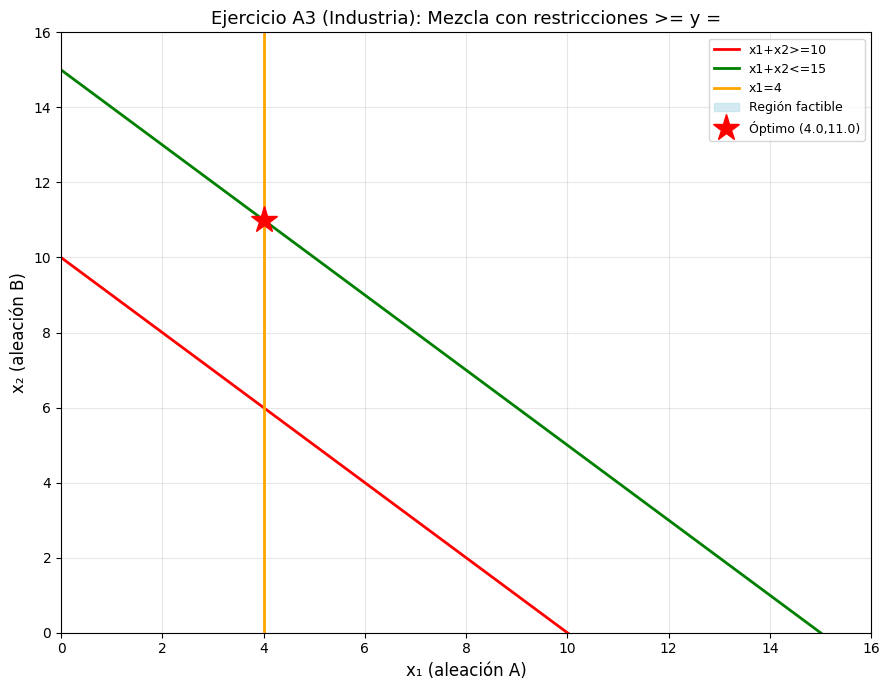


--- PASO 7: ANÁLISIS DE SENSIBILIDAD ---
Precios sombra:
  y1 (mínimo total) = 0 (la restricción ya se cumple)
  y2 (capacidad)    = 0 (sobra capacidad)
  Restricción x1=4  = 400 (es un compromiso obligatorio)

Holguras en el óptimo:
  e1 = 0 (se produce exactamente 10)
  s3 = 5 (sobran 5 ton de capacidad)

--- PASO 8: CONCLUSIÓN INDUSTRIAL ---
1. Producir 4 ton de A (obligatorio) y 6 ton de B.
2. Ganancia máxima: $3,400.
3. La restricción de mínimo total está activa.
4. La capacidad máxima tiene holgura (sobran 5 ton).
5. Si se pudiera reducir el mínimo de 10 a 9, la ganancia
   bajaría en $300 (porque B da menos ganancia que A).
6. Este ejercicio muestra el uso de Fase I y Fase II.


In [1]:
# =====================================================================
# EJERCICIO A3 (INDUSTRIA): Mezcla con restricciones >= y =
# =====================================================================
# PROBLEMA:
#   Planta química produce aleación A (x1) y B (x2).
#   Ganancia: $400/ton de A, $300/ton de B.
#   Restricciones:
#     x1 + x2 >= 10  (mínimo total)
#     x1       = 4   (compromiso exacto)
#     x1 + x2 <= 15  (capacidad máxima)
#
# OBJETIVO: maximizar ganancia.
# =====================================================================

import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import linprog

print("="*70)
print("EJERCICIO A3 (INDUSTRIA): MEZCLA CON RESTRICCIONES >= Y =")
print("="*70)

# ---------------------------------------------------------------------
# PASO 1: MODELO MATEMÁTICO
# ---------------------------------------------------------------------
print("\n--- PASO 1: MODELO MATEMÁTICO ---")
print("Variables de decisión:")
print("  x1 = toneladas de aleación A")
print("  x2 = toneladas de aleación B")
print("\nFunción objetivo:")
print("  max z = 400*x1 + 300*x2")
print("\nRestricciones:")
print("  x1 + x2 >= 10  (mínimo total)")
print("  x1       = 4   (compromiso exacto)")
print("  x1 + x2 <= 15  (capacidad máxima)")
print("  x1, x2 >= 0")

# ---------------------------------------------------------------------
# PASO 2: FORMA ESTÁNDAR (con exceso y artificiales)
# ---------------------------------------------------------------------
print("\n--- PASO 2: FORMA ESTÁNDAR ---")
print("Restricción >= : se agrega exceso e1 y artificial a1:")
print("  x1 + x2 - e1 + a1 = 10")
print("Restricción =  : se agrega artificial a2:")
print("  x1 + a2 = 4")
print("Restricción <= : se agrega holgura s3:")
print("  x1 + x2 + s3 = 15")
print("\nBase inicial: {a1, a2, s3} -> se usa Fase I")

# ---------------------------------------------------------------------
# PASO 3: FASE I (minimizar suma de artificiales)
# ---------------------------------------------------------------------
print("\n--- PASO 3: FASE I (minimizar w = a1 + a2) ---")
print("Tabla inicial de Fase I:")
print(f"{'Base':<8}{'x1':>8}{'x2':>8}{'e1':>8}{'a1':>8}{'a2':>8}{'s3':>8}{'Sol':>10}")
print("-"*66)
print(f"{'a1':<8}{1:>8}{1:>8}{-1:>8}{1:>8}{0:>8}{0:>8}{10:>10}")
print(f"{'a2':<8}{1:>8}{0:>8}{0:>8}{0:>8}{1:>8}{0:>8}{4:>10}")
print(f"{'s3':<8}{1:>8}{1:>8}{0:>8}{0:>8}{0:>8}{1:>8}{15:>10}")
print(f"{'w':<8}{2:>8}{1:>8}{-1:>8}{0:>8}{0:>8}{0:>8}{14:>10}")

print("\n>>> Iteración 1: entra x1, sale a2 (razón 4/1=4)")
print(">>> Iteración 2: entra x2, sale a1 (razón 6/1=6)")
print(">>> Fase I termina con w = 0 -> hay solución factible")
print(">>> Base inicial para Fase II: {x2, x1, s3}")

# ---------------------------------------------------------------------
# PASO 4: FASE II (optimizar z)
# ---------------------------------------------------------------------
print("\n--- PASO 4: FASE II (optimizar z = 400x1 + 300x2) ---")
print("Desde la base {x2=6, x1=4, s3=5}:")
print("  x1 = 4")
print("  x2 = 6 + e1")
print("  s3 = 5 - e1")
print("  z = 400(4) + 300(6 + e1) = 3400 + 300*e1")
print("\n>>> Como e1 >= 0 y su coeficiente es +300, no conviene aumentarla.")
print(">>> Todos los costos reducidos >= 0 -> ÓPTIMO")

# ---------------------------------------------------------------------
# PASO 5: VERIFICACIÓN CON LINPROG
# ---------------------------------------------------------------------
print("\n--- PASO 5: VERIFICACIÓN CON SCIPY ---")
c = [-400, -300]
A_ub = [[-1, -1], [1, 1]]
b_ub = [-10, 15]
A_eq = [[1, 0]]
b_eq = [4]
bounds = [(0, None), (0, None)]

res = linprog(c, A_ub=A_ub, b_ub=b_ub, A_eq=A_eq, b_eq=b_eq,
              bounds=bounds, method='highs')
print(f"  x1 = {res.x[0]:.4f}")
print(f"  x2 = {res.x[1]:.4f}")
print(f"  z  = {-res.fun:.4f}")

# ---------------------------------------------------------------------
# PASO 6: GRÁFICO
# ---------------------------------------------------------------------
print("\n--- PASO 6: GRÁFICO ---")

fig, ax = plt.subplots(figsize=(9, 7))

x = np.linspace(0, 16, 400)
ax.plot(x, 10 - x, 'r-', linewidth=2, label='x1+x2>=10')
ax.plot(x, 15 - x, 'g-', linewidth=2, label='x1+x2<=15')
ax.axvline(x=4, color='orange', linewidth=2, label='x1=4')

# Región factible: x1=4, 6<=x2<=11
ax.fill_between([4, 4], [6, 11], [11, 6], color='lightblue', alpha=0.5,
                label='Región factible')

ax.plot(res.x[0], res.x[1], 'r*', markersize=20,
        label=f'Óptimo ({res.x[0]:.1f},{res.x[1]:.1f})')

ax.set_xlim(0, 16)
ax.set_ylim(0, 16)
ax.set_xlabel('x₁ (aleación A)', fontsize=12)
ax.set_ylabel('x₂ (aleación B)', fontsize=12)
ax.set_title('Ejercicio A3 (Industria): Mezcla con restricciones >= y =',
             fontsize=13)
ax.grid(True, alpha=0.3)
ax.legend(fontsize=9, loc='best')
plt.tight_layout()
plt.show()

# ---------------------------------------------------------------------
# PASO 7: ANÁLISIS DE SENSIBILIDAD
# ---------------------------------------------------------------------
print("\n--- PASO 7: ANÁLISIS DE SENSIBILIDAD ---")
print("Precios sombra:")
print("  y1 (mínimo total) = 0 (la restricción ya se cumple)")
print("  y2 (capacidad)    = 0 (sobra capacidad)")
print("  Restricción x1=4  = 400 (es un compromiso obligatorio)")
print("\nHolguras en el óptimo:")
print("  e1 = 0 (se produce exactamente 10)")
print("  s3 = 5 (sobran 5 ton de capacidad)")

# ---------------------------------------------------------------------
# PASO 8: CONCLUSIÓN INDUSTRIAL
# ---------------------------------------------------------------------
print("\n--- PASO 8: CONCLUSIÓN INDUSTRIAL ---")
print("1. Producir 4 ton de A (obligatorio) y 6 ton de B.")
print("2. Ganancia máxima: $3,400.")
print("3. La restricción de mínimo total está activa.")
print("4. La capacidad máxima tiene holgura (sobran 5 ton).")
print("5. Si se pudiera reducir el mínimo de 10 a 9, la ganancia")
print("   bajaría en $300 (porque B da menos ganancia que A).")
print("6. Este ejercicio muestra el uso de Fase I y Fase II.")
print("="*70)